In [2]:
import pandas as pd
import numpy as np

In [3]:
df1 = pd.read_csv("/kaggle/input/competitions/house-price-prediction-challenge-regression/estate_train.csv")
df2 = pd.read_csv("/kaggle/input/competitions/house-price-prediction-challenge-regression/estate_test.csv")

In [4]:
train_df = df1.copy()
test_df = df2.copy()

In [5]:
print("Train data shape is",train_df.shape)
print("Test data shape is ", test_df.shape)

Train data shape is (16512, 12)
Test data shape is  (4128, 11)


In [6]:
train_df.head()

,IncomeLevel,PropertyAge,TotalRooms,TotalBedrooms,NeighborhoodPop,AvgOccupancy,Latitude,Longitude,TargetPrice,PropertyID,RoomsPerHousehold,BedroomsRatio
0,3.287977,32.970198,5.128150,0.990769,2339.474039,3.739113,32.71,-117.03,1.030,PROP_14196,1.359130,0.200576
1,3.804601,49.030192,4.372696,1.040469,1269.383596,1.429576,33.77,-118.16,3.821,PROP_08267,2.573820,0.232703
2,4.193302,NaN,5.718626,0.989809,865.436104,2.481219,34.66,-120.48,1.726,PROP_17445,2.073224,0.174486
3,2.029509,36.255617,4.131418,1.032285,1455.381923,3.914447,32.69,-117.11,0.934,PROP_14265,1.002116,0.258269
4,3.540823,42.918534,6.270531,1.147146,895.050628,2.681969,36.78,-119.80,0.965,PROP_02271,2.725400,0.180940


In [7]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16512 entries, 0 to 16511
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   IncomeLevel        16512 non-null  float64
 1   PropertyAge        15199 non-null  float64
 2   TotalRooms         16512 non-null  float64
 3   TotalBedrooms      16512 non-null  float64
 4   NeighborhoodPop    16512 non-null  float64
 5   AvgOccupancy       16512 non-null  float64
 6   Latitude           16512 non-null  float64
 7   Longitude          16512 non-null  float64
 8   TargetPrice        16512 non-null  float64
 9   PropertyID         16512 non-null  object 
 10  RoomsPerHousehold  16512 non-null  float64
 11  BedroomsRatio      16512 non-null  float64
dtypes: float64(11), object(1)
memory usage: 1.5+ MB


In [8]:
train_df.describe()

,IncomeLevel,PropertyAge,TotalRooms,TotalBedrooms,NeighborhoodPop,AvgOccupancy,Latitude,Longitude,TargetPrice,RoomsPerHousehold,BedroomsRatio
count,16512.000000,15199.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000
mean,3.880870,28.610537,5.435311,1.096797,1426.441888,3.097123,35.643149,-119.582290,2.071947,1.980582,0.212858
std,1.906229,12.604955,2.387346,0.433573,1137.594296,11.589701,2.136665,2.005654,1.156226,1.125818,0.057995
min,0.409295,0.567139,0.973695,0.329765,-44.578990,0.579087,32.550000,-124.350000,0.149990,0.002547,0.100000
25%,2.564153,18.195306,4.450483,1.005528,788.555955,2.362349,33.930000,-121.810000,1.198000,1.526243,0.175178
50%,3.544769,28.747429,5.238836,1.049505,1169.707835,2.835532,34.260000,-118.510000,1.798500,1.941541,0.202808
75%,4.779065,37.045296,6.064049,1.102542,1730.584980,3.364962,37.720000,-118.010000,2.651250,2.300615,0.239501
max,15.113356,53.490497,141.875493,25.630214,35739.248210,1243.662159,41.950000,-114.310000,5.000010,52.033333,1.000000


In [9]:
train_df[train_df["NeighborhoodPop"]<0].count()

IncomeLevel          20
PropertyAge          17
TotalRooms           20
TotalBedrooms        20
NeighborhoodPop      20
AvgOccupancy         20
Latitude             20
Longitude            20
TargetPrice          20
PropertyID           20
RoomsPerHousehold    20
BedroomsRatio        20
dtype: int64

In [10]:
print("NaN missing values:",train_df.isnull().sum())
print("Empty missing values:",(train_df == ' ').sum().sum())
print("Other missing values:",(train_df.isin(['NA', 'N/A', '-',"?"])).sum().sum())
print("UNKNOWN missing values:",(train_df == 'UNKNOWN').sum().sum())
print("Unknown missing values:",(train_df == 'Unknown').sum().sum())

NaN missing values: IncomeLevel             0
PropertyAge          1313
TotalRooms              0
TotalBedrooms           0
NeighborhoodPop         0
AvgOccupancy            0
Latitude                0
Longitude               0
TargetPrice             0
PropertyID              0
RoomsPerHousehold       0
BedroomsRatio           0
dtype: int64
Empty missing values: 0
Other missing values: 0
UNKNOWN missing values: 0
Unknown missing values: 0


In [11]:
train_df.nunique().sort_values()

Longitude              833
Latitude               845
TargetPrice           3675
PropertyAge          15199
BedroomsRatio        15836
RoomsPerHousehold    16295
TotalBedrooms        16512
IncomeLevel          16512
NeighborhoodPop      16512
AvgOccupancy         16512
TotalRooms           16512
PropertyID           16512
dtype: int64

array([[<Axes: title={'center': 'IncomeLevel'}>,
        <Axes: title={'center': 'PropertyAge'}>,
        <Axes: title={'center': 'TotalRooms'}>],
       [<Axes: title={'center': 'TotalBedrooms'}>,
        <Axes: title={'center': 'NeighborhoodPop'}>,
        <Axes: title={'center': 'AvgOccupancy'}>],
       [<Axes: title={'center': 'Latitude'}>,
        <Axes: title={'center': 'Longitude'}>,
        <Axes: title={'center': 'TargetPrice'}>],
       [<Axes: title={'center': 'RoomsPerHousehold'}>,
        <Axes: title={'center': 'BedroomsRatio'}>, <Axes: >]],
      dtype=object)

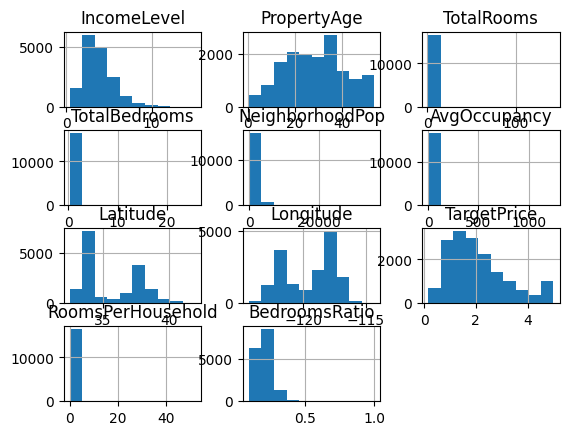

In [12]:

train_df.hist()

# Feature Engineering

In [13]:
y = train_df["TargetPrice"]
X = train_df.drop(["PropertyID","TargetPrice"],axis = 1)

In [14]:
from sklearn.model_selection import train_test_split
X_train,X_val,y_train,y_val = train_test_split(X,y,test_size=0.2,random_state = 42)

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid') 

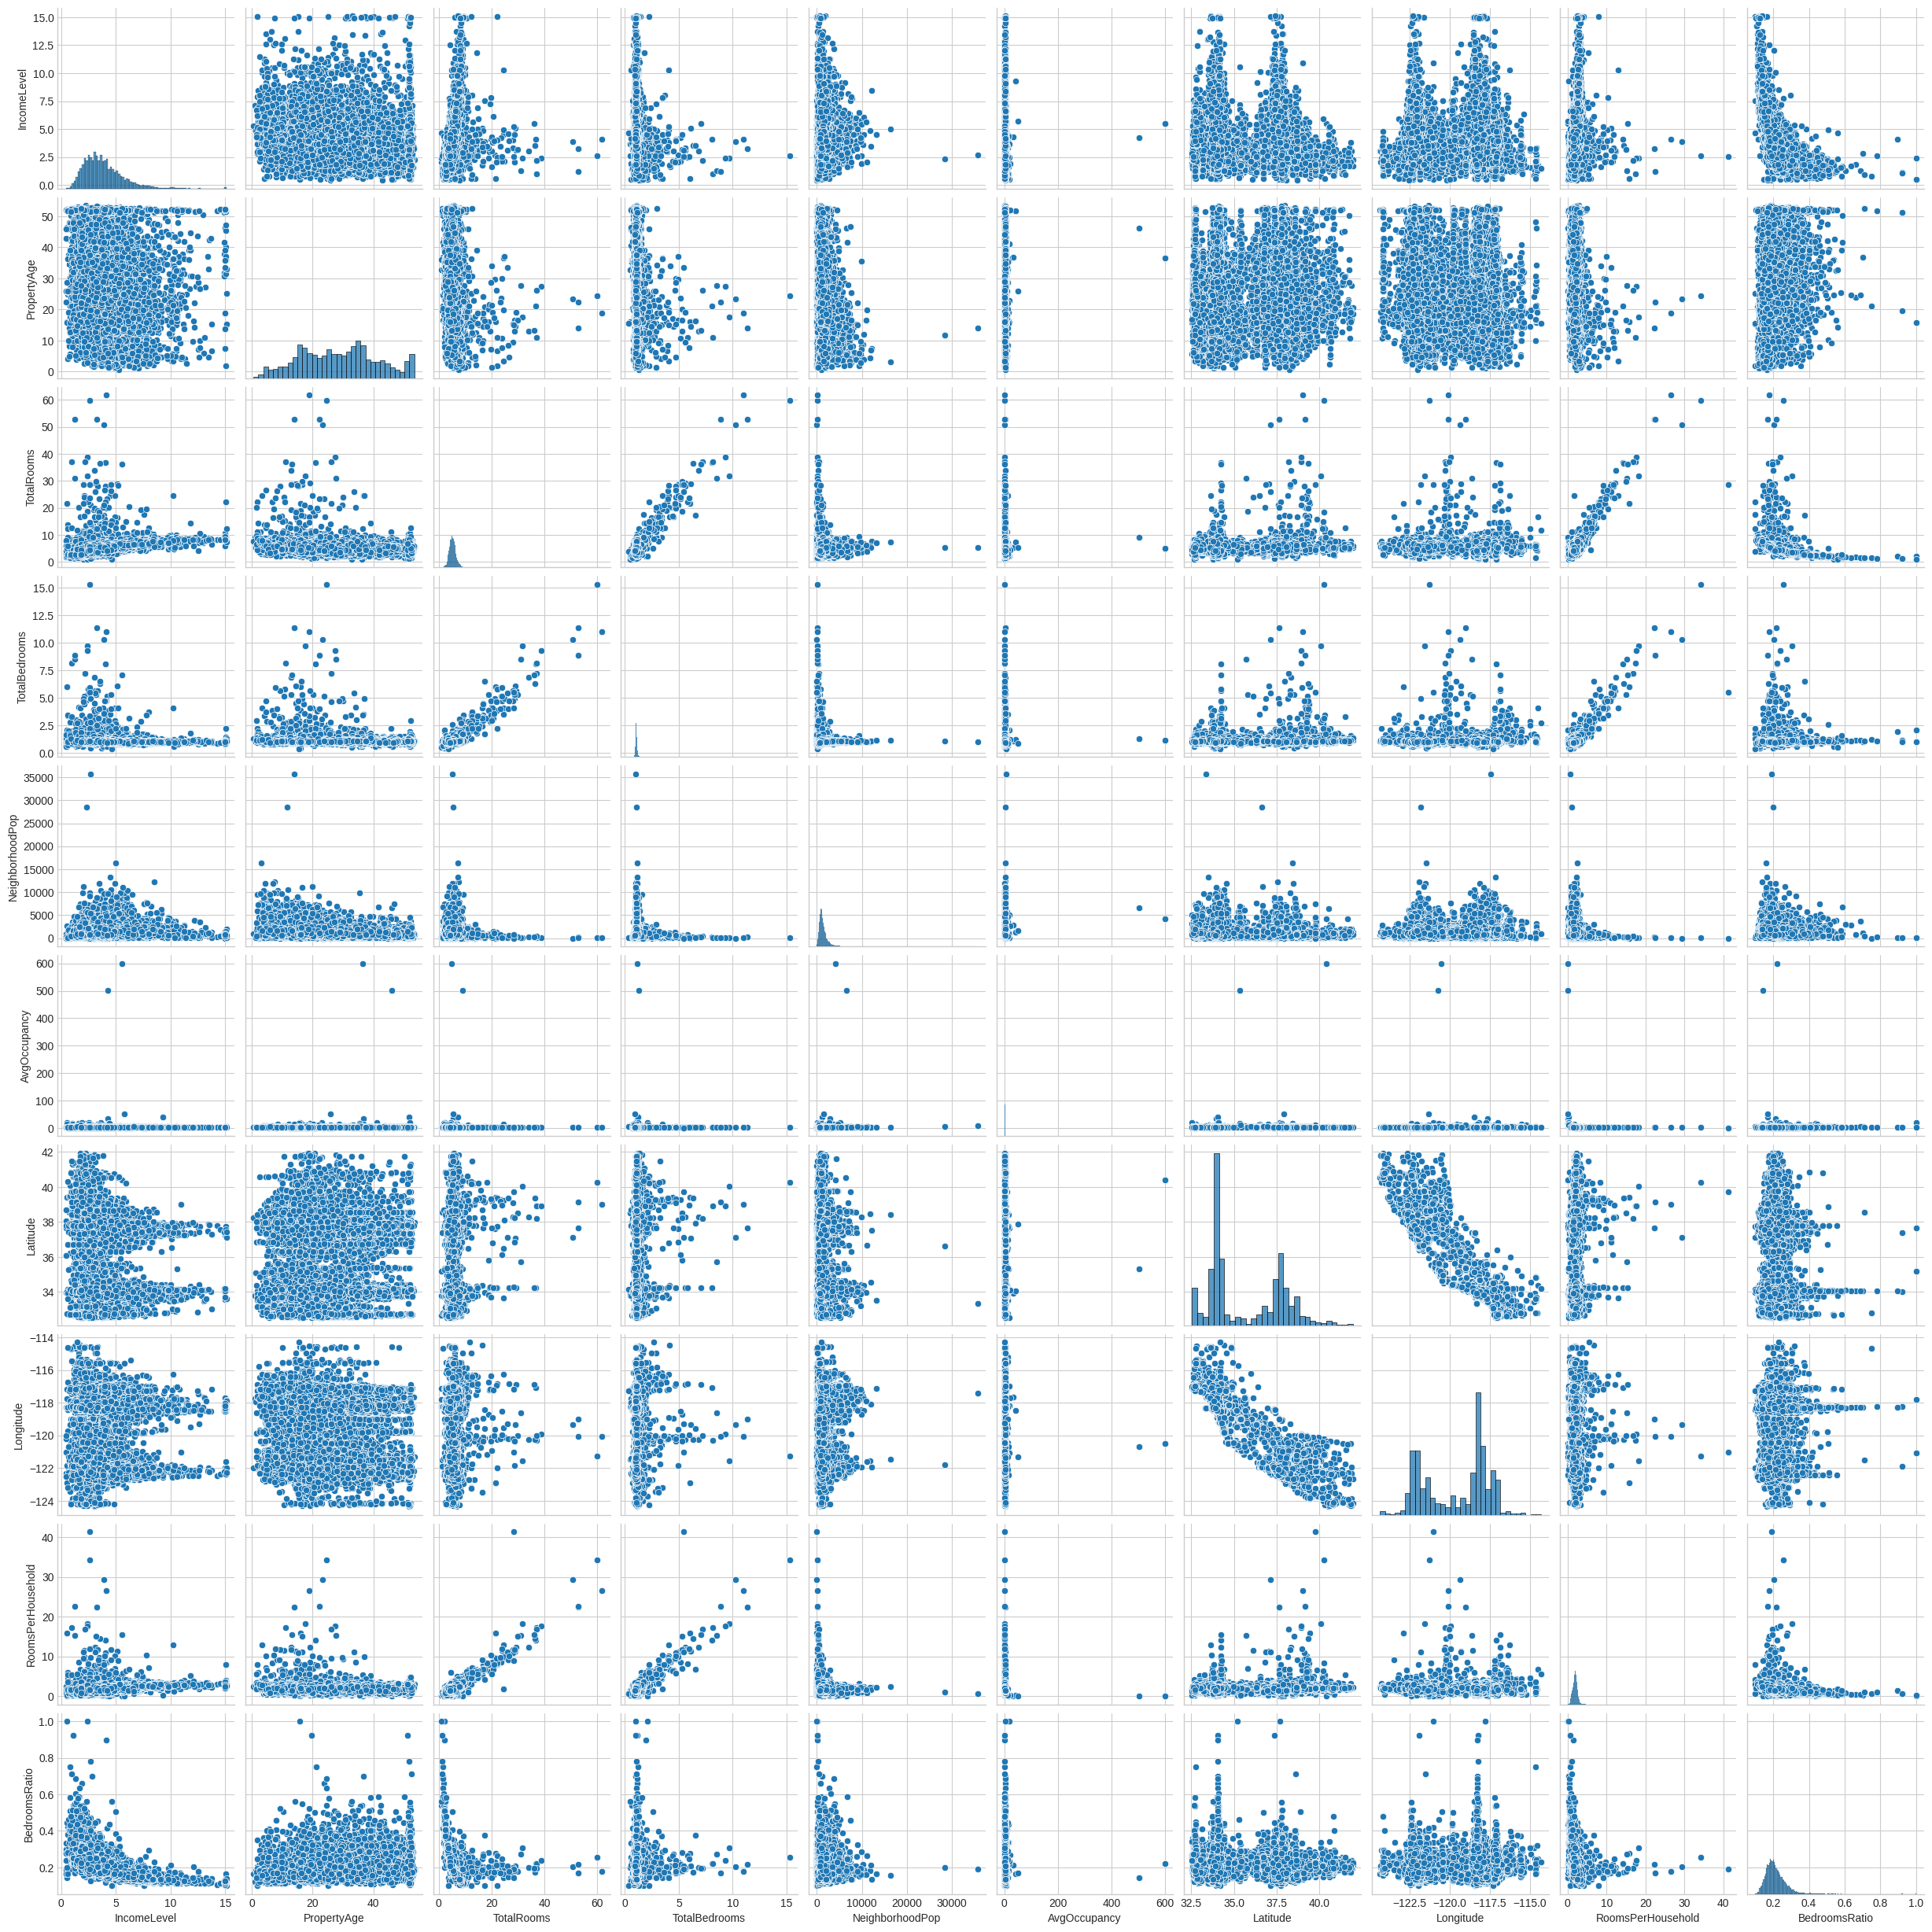

In [16]:
sns.pairplot(X_train)

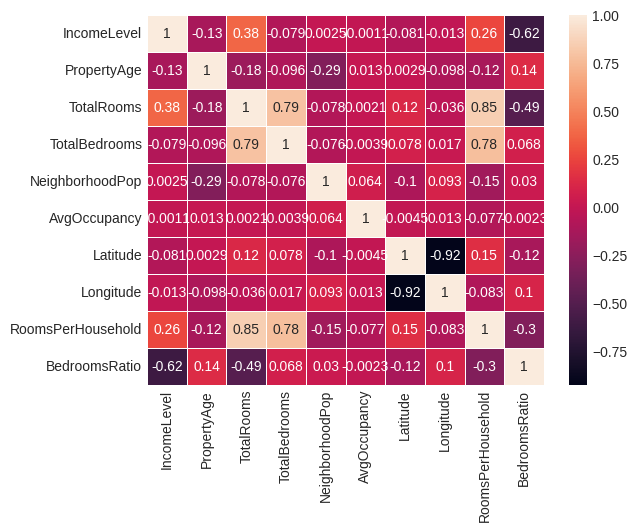

<Figure size 2000x2000 with 0 Axes>

In [17]:
correlation_martrix = X_train.corr()
sns.heatmap(correlation_martrix, annot = True,linewidth = .5)
plt.figure(figsize = (20,20))
plt.show()

In [18]:
correlation_table = X_train.select_dtypes("number").corr()
correlation_table

,IncomeLevel,PropertyAge,TotalRooms,TotalBedrooms,NeighborhoodPop,AvgOccupancy,Latitude,Longitude,RoomsPerHousehold,BedroomsRatio
IncomeLevel,1.000000,-0.125647,0.382121,-0.079365,0.002548,-0.001118,-0.080796,-0.013148,0.260879,-0.616379
PropertyAge,-0.125647,1.000000,-0.177701,-0.095517,-0.289924,0.013091,0.002893,-0.098230,-0.123039,0.135461
TotalRooms,0.382121,-0.177701,1.000000,0.789525,-0.077914,0.002104,0.121252,-0.035772,0.849734,-0.488849
TotalBedrooms,-0.079365,-0.095517,0.789525,1.000000,-0.075628,-0.003889,0.077950,0.016655,0.776961,0.068262
NeighborhoodPop,0.002548,-0.289924,-0.077914,-0.075628,1.000000,0.063698,-0.102264,0.093478,-0.151918,0.030452
AvgOccupancy,-0.001118,0.013091,0.002104,-0.003889,0.063698,1.000000,-0.004478,0.012995,-0.077289,-0.002327
Latitude,-0.080796,0.002893,0.121252,0.077950,-0.102264,-0.004478,1.000000,-0.924648,0.151094,-0.121119
Longitude,-0.013148,-0.098230,-0.035772,0.016655,0.093478,0.012995,-0.924648,1.000000,-0.083048,0.099603
RoomsPerHousehold,0.260879,-0.123039,0.849734,0.776961,-0.151918,-0.077289,0.151094,-0.083048,1.000000,-0.298551
BedroomsRatio,-0.616379,0.135461,-0.488849,0.068262,0.030452,-0.002327,-0.121119,0.099603,-0.298551,1.000000


In [19]:
features = X_train.columns.tolist()
features

['IncomeLevel',
 'PropertyAge',
 'TotalRooms',
 'TotalBedrooms',
 'NeighborhoodPop',
 'AvgOccupancy',
 'Latitude',
 'Longitude',
 'RoomsPerHousehold',
 'BedroomsRatio']

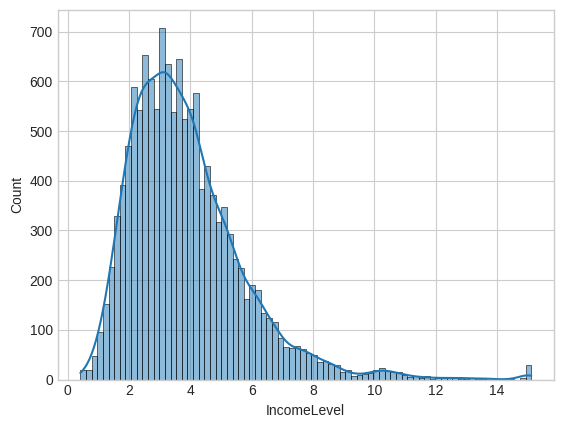

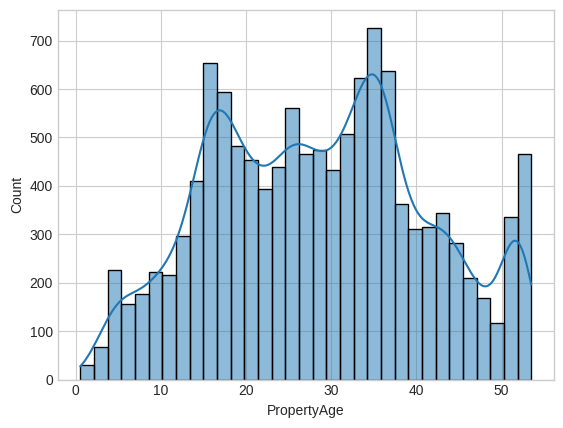

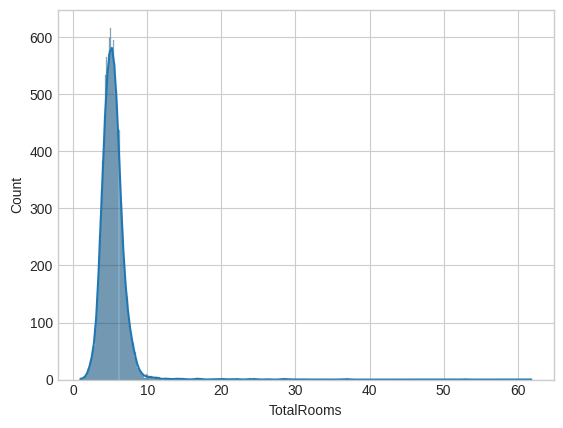

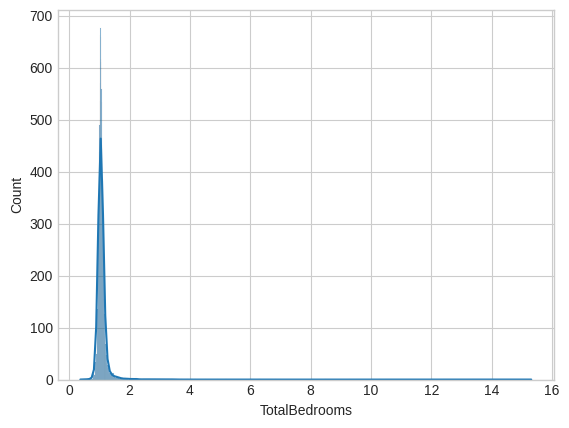

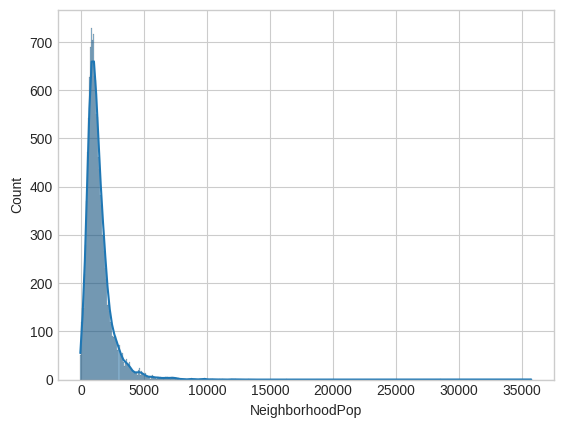

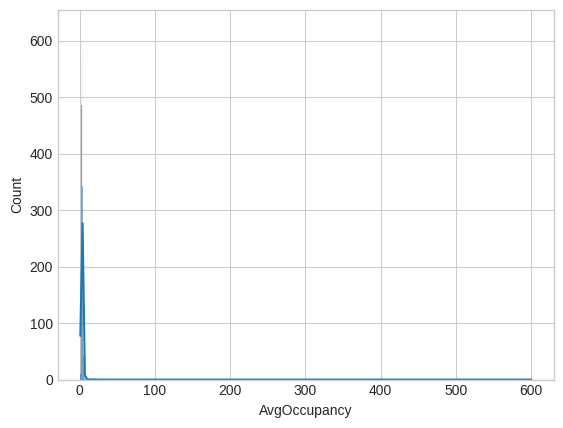

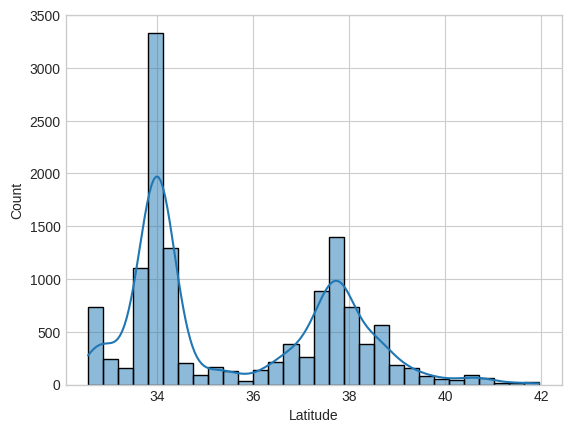

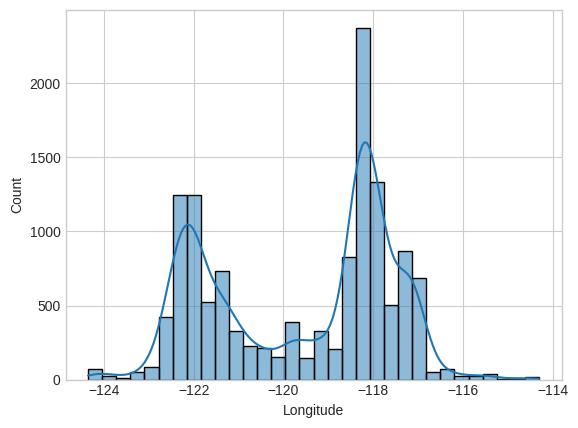

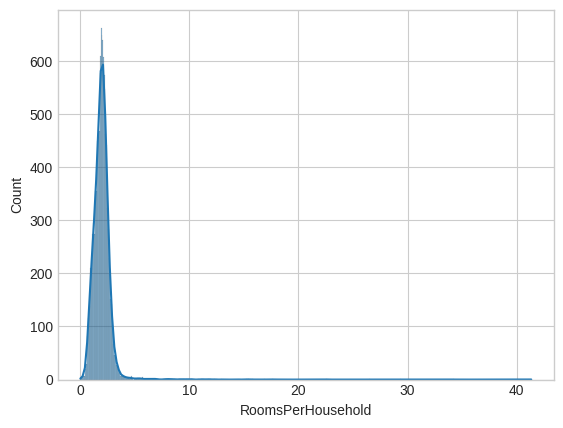

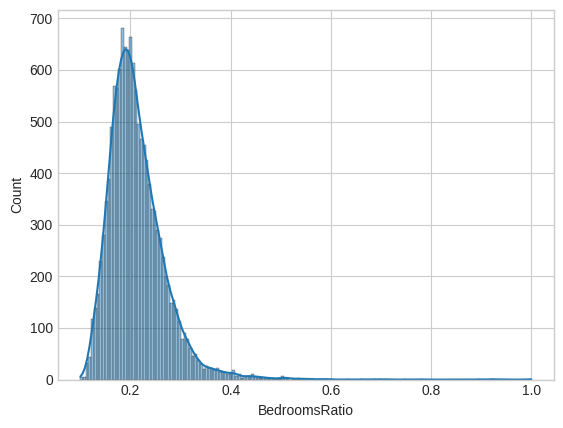

In [20]:
for col in features:
    sns.histplot(X_train,x= col , kde = True)
    plt.show()

In [21]:
from sklearn.model_selection import ShuffleSplit, cross_val_score,cross_validate
cv = ShuffleSplit(n_splits=10, test_size=0.2, random_state=42)

In [22]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

In [23]:
transform_pipeline = Pipeline([("imputer",SimpleImputer(strategy = "median")),
                               ("stdscalar",StandardScaler())])
X_train_transformed = transform_pipeline.fit_transform(X_train)
X_val_transformed =  transform_pipeline.fit_transform(X_val)

# Model Training

In [24]:
from sklearn.metrics import root_mean_squared_error

In [25]:
from sklearn.dummy import DummyRegressor

dummy_reg = DummyRegressor(strategy = "mean")
dummy_reg.fit(X_train_transformed,y_train)

y_pred_train = dummy_reg.predict(X_train_transformed)
print("Training error is ", root_mean_squared_error(y_train,y_pred_train))

y_pred_val = dummy_reg.predict(X_val)
print("Validation error is ", root_mean_squared_error(y_val,y_pred_val))

Training error is  1.1514542450342449
Validation error is  1.1749979071738703


In [26]:
from sklearn.linear_model import LinearRegression

lin_reg_pipeline = Pipeline([("imputer",SimpleImputer(strategy="mean")),
                              ("Scaler",StandardScaler()),
                              ("lin_reg",LinearRegression())])

lin_reg_cv_results = cross_validate(lin_reg_pipeline,
                                    X,
                                    y,
                                    cv=cv,
                                    scoring="neg_root_mean_squared_error",
                                    return_train_score=True,
                                    return_estimator=True)

lin_reg_train_error = -1 * lin_reg_cv_results['train_score']
lin_reg_test_error = -1 * lin_reg_cv_results['test_score']

print(f"Mean absolute error of linear regression model on the train set:\n"
      f"{lin_reg_train_error.mean():.3f} +/- {lin_reg_train_error.std():.3f}")
print(f"Mean absolute error of linear regression model on the test set:\n"
      f"{lin_reg_test_error.mean():.3f} +/- {lin_reg_test_error.std():.3f}")
lin_reg_pipeline.fit(X_train,y_train)

y_pred = lin_reg_pipeline.predict(X_train)


Mean absolute error of linear regression model on the train set:
0.679 +/- 0.006
Mean absolute error of linear regression model on the test set:
0.681 +/- 0.025


In [27]:
poly_reg_pipeline = Pipeline([("imputer",SimpleImputer(strategy="mean")),
                              ("poly", PolynomialFeatures(degree=2)),
                              ("feature_scaling", StandardScaler()),
                              ("lin_reg", LinearRegression())])
poly_reg_cv_results = cross_validate(poly_reg_pipeline,
                                    X,
                                    y,
                                    cv=cv,
                                    scoring="neg_mean_absolute_error",
                                    return_train_score=True,
                                    return_estimator=True)

poly_reg_train_error = -1 * poly_reg_cv_results['train_score']
poly_reg_test_error = -1 * poly_reg_cv_results['test_score']

print(f"Mean absolute error of linear regression model on the train set:\n"
      f"{poly_reg_train_error.mean():.3f} +/- {poly_reg_train_error.std():.3f}")
print(f"Mean absolute error of linear regression model on the test set:\n"
      f"{poly_reg_test_error.mean():.3f} +/- {poly_reg_test_error.std():.3f}")

Mean absolute error of linear regression model on the train set:
0.433 +/- 0.002
Mean absolute error of linear regression model on the test set:
0.563 +/- 0.223


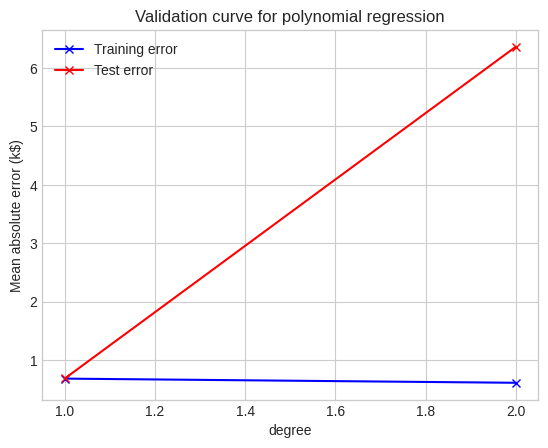

In [28]:
from sklearn.model_selection import validation_curve

degree = [1, 2]
train_scores, test_scores = validation_curve(
    poly_reg_pipeline, X, y, param_name="poly__degree",
    param_range=degree, cv=cv, scoring="neg_root_mean_squared_error",
    n_jobs=2)

train_errors, test_errors = -train_scores, -test_scores
plt.plot(degree, train_errors.mean(axis=1), 'b-x', label="Training error")
plt.plot(degree, test_errors.mean(axis=1), 'r-x', label="Test error")
plt.legend()

plt.xlabel("degree")
plt.ylabel("Mean absolute error (k$)")
_ = plt.title("Validation curve for polynomial regression")

In [29]:
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import Ridge
from sklearn.linear_model import LassoCV
from sklearn.linear_model import Lasso

In [30]:
ridge_reg_pipeline = Pipeline([("imputer",SimpleImputer(strategy="mean")),
                              ("Scaler",StandardScaler()),
                              ("ridge", Ridge(alpha=0.5))])
ridge_reg_cv_results = cross_validate(ridge_reg_pipeline,
                                    X,
                                    y,
                                    cv=cv,
                                    scoring="neg_root_mean_squared_error",
                                    return_train_score=True,
                                    return_estimator=True)

ridge_reg_train_error = -1 * ridge_reg_cv_results['train_score']
ridge_reg_test_error = -1 * ridge_reg_cv_results['test_score']

print(f"Mean absolute error of ridge regression model (alpha=0.5) on the train set:\n"
      f"{ridge_reg_train_error.mean():.3f} +/- {ridge_reg_train_error.std():.3f}")
print(f"Mean absolute error of ridge regression model (alpha=0.5) on the test set:\n"
      f"{ridge_reg_test_error.mean():.3f} +/- {ridge_reg_test_error.std():.3f}")

Mean absolute error of ridge regression model (alpha=0.5) on the train set:
0.679 +/- 0.006
Mean absolute error of ridge regression model (alpha=0.5) on the test set:
0.681 +/- 0.025


In [31]:
lasso_reg_pipeline = Pipeline([("imputer",SimpleImputer(strategy="mean")),
                              ("Scaler",StandardScaler()),
                              ("lasso", Lasso(alpha=0.01))])
lasso_reg_cv_results = cross_validate(lasso_reg_pipeline,
                                    X,
                                    y,
                                    cv=cv,
                                    scoring="neg_mean_absolute_error",
                                    return_train_score=True,
                                    return_estimator=True)

lasso_reg_train_error = -1 * lasso_reg_cv_results['train_score']
lasso_reg_test_error = -1 * lasso_reg_cv_results['test_score']

print(f"Mean absolute error of linear regression model on the train set:\n"
      f"{lasso_reg_train_error.mean():.3f} +/- {ridge_reg_train_error.std():.3f}")
print(f"Mean absolute error of linear regression model on the test set:\n"
      f"{lasso_reg_test_error.mean():.3f} +/- {ridge_reg_test_error.std():.3f}")

Mean absolute error of linear regression model on the train set:
0.490 +/- 0.006
Mean absolute error of linear regression model on the test set:
0.492 +/- 0.025


In [32]:
from sklearn.tree import DecisionTreeRegressor

In [33]:
tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("tree", DecisionTreeRegressor(random_state=42,max_depth=5))
])


tree_cv_results = cross_validate(
    tree_pipeline,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    return_train_score=True,
    return_estimator=True
)


tree_train_error = -tree_cv_results["train_score"]
tree_cv_error = -tree_cv_results["test_score"]

print(
    f"Mean training RMSE from CV: "
    f"{tree_train_error.mean():.3f} +/- {tree_train_error.std():.3f}"
)

print(
    f"Mean validation RMSE from CV: "
    f"{tree_cv_error.mean():.3f} +/- {tree_cv_error.std():.3f}"
)



Mean training RMSE from CV: 0.718 +/- 0.005
Mean validation RMSE from CV: 0.746 +/- 0.014


In [34]:
for depth in [2, 3, 5, 7, 10, 15, 20, None]:

    tree_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("tree", DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        ))
    ])

    results = cross_validate(
        tree_pipeline,
        X,
        y,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    cv_rmse = -results["test_score"].mean()

    print(f"max_depth={depth}: CV RMSE = {cv_rmse:.3f}")

max_depth=2: CV RMSE = 0.865
max_depth=3: CV RMSE = 0.814
max_depth=5: CV RMSE = 0.746
max_depth=7: CV RMSE = 0.696
max_depth=10: CV RMSE = 0.663
max_depth=15: CV RMSE = 0.728
max_depth=20: CV RMSE = 0.744
max_depth=None: CV RMSE = 0.745


In [35]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

tree_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("tree", DecisionTreeRegressor(random_state=42))
])

param_grid = {
    "tree__max_depth": [7, 8, 9, 10, 11, 12],
    "tree__min_samples_leaf": [1, 2, 5, 10, 20],
    "tree__min_samples_split": [2, 5, 10, 20]
}

grid_search = GridSearchCV(
    tree_pipeline,
    param_grid,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X, y)

print("Best parameters:", grid_search.best_params_)
print("Best CV RMSE:", -grid_search.best_score_)

Best parameters: {'tree__max_depth': 12, 'tree__min_samples_leaf': 20, 'tree__min_samples_split': 2}
Best CV RMSE: 0.6224370976068871


In [36]:
lasso_reg_pipeline.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer()), ('Scaler', StandardScaler()),
                ('lasso', Lasso(alpha=0.01))])

In [37]:
from sklearn.ensemble import RandomForestRegressor

In [38]:
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("rf", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])


rf_cv_results = cross_validate(
    rf_pipeline,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    return_train_score=True,
    return_estimator=True
)


rf_train_error = -rf_cv_results["train_score"]
rf_cv_error = -rf_cv_results["test_score"]

print(
    f"Mean training RMSE from CV: "
    f"{rf_train_error.mean():.3f} +/- {rf_train_error.std():.3f}"
)

print(
    f"Mean validation RMSE from CV: "
    f"{rf_cv_error.mean():.3f} +/- {rf_cv_error.std():.3f}"
)


Mean training RMSE from CV: 0.191 +/- 0.001
Mean validation RMSE from CV: 0.517 +/- 0.011


In [39]:
rf_pipeline.fit(X, y)

Pipeline(steps=[('imputer', SimpleImputer()),
                ('rf',
                 RandomForestRegressor(n_estimators=300, n_jobs=-1,
                                       random_state=42))])

In [40]:
test_property_ids = test_df["PropertyID"]
X_test = test_df.drop(columns=["PropertyID"])
predictions = rf_pipeline.predict(X_test)
submission = pd.DataFrame({
    "PropertyID": test_property_ids,
    "TargetPrice": predictions
})
submission.to_csv("submission.csv", index=False)